# 01. Pedigree BLUP в rrBLUP


In [1]:
knitr::opts_chunk$set(
  echo = TRUE,
  message = FALSE,
  warning = FALSE,
  fig.width = 9,
  fig.height = 5
)


In [2]:
fix_categorical_effects = c('event_season', 'event_year')
fix_numerical_effects = c('dam_age', 'okot_massa', 'okot_number')
random_categorical_effects = 'economy'
is_random = FALSE
diagonal_coefficient = 0.2


---
title: "01. Pedigree BLUP в rrBLUP"
date: "`Sys.Date()`"
output:
  html_document:
    toc: true
    toc_depth: 3
    toc_float:
      collapsed: false
    theme: flatly
    highlight: tango
    df_print: paged
---


# О документе

Отчёт считает оценку племенной ценности **только по родословной**, без SNP.

| | |
|---|---|
| **Данные** | `data/pedigree.csv`, `data/phenotypes.csv` |
| **Цель** | Собрать матрицы A, X, Z и получить EBV через `mixed.solve` |
| **Результат** | EBV, стандартная ошибка и reliability для каждого животного |


In [3]:
library(rrBLUP)
library(AGHmatrix)
library(Matrix)
library(pedigreeTools)
library(dplyr)
library(ggplot2)
library(tidyr)
library(e1071)
library(knitr)



Attaching package: ‘dplyr’



The following objects are masked from ‘package:stats’:

    filter, lag



The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




Attaching package: ‘tidyr’



The following objects are masked from ‘package:Matrix’:

    expand, pack, unpack



# Вступление

Оценка племенной ценности методом BLUP (Best Linear Unbiased Prediction) является стандартом в генетике животных. Несмотря на широкое распространение специализированного програмного обеспечения, такого как семейство программ BLUPF90, в некоторых случаях может быть целесообразно реализовать расчёт вручную с помощью языка R. Это позволяет получить полный контроль над моделью, гибко адаптировать структуру данных, визуализировать промежуточные шаги и глубже понять математическую сущность модели.

Преимущества расчёта в среде R по сравнению с расчётом с помощью программы BLUPF90:

- Гибкость в модели. Возможность свободно варьировать структуру фиксированных и случаёных эффектов;

- Прозрачность алгоритма. Все необходимые матрицы создаются вручную. Мы видим, что происходит;

- Визуализация и диагностика. Можно сделать любую визуализацию на каждом этапе;

- Удобная отладка. При ошибке можно локализовать этап, где возникла проблема;

- Возможность включения новых алгоритмов. Можно добавить любой алгоритм, который повысит точность полученной оценки

В данной работе была применена простая линейная модель для оценки племенной ценности животных методом BLUP.

# 1. Загрузка данных

В первую очередь необходимо загрузить необходимые нам данные: 

- Данные родословной;

- Фенотипические данные.

Это обязательные данные для расчёта качественной оценки. Таблицы читаются из CSV, заранее сохранённых скриптом `tools/generate_data.R`.


In [4]:
phenotypes <- read.csv('data/phenotypes.csv') %>%
  dplyr::select(animal, okot_massa, okot_number, dam_age, event_season, event_year, trait)
pedigree <- read.csv('data/pedigree.csv')
common_levels <- levels(as.factor(unique(c(phenotypes$animal, pedigree$animal, pedigree$dam, pedigree$sire))))


In [5]:
print(knitr::kable(head(pedigree, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      1|    0|   0|
|      2|    0|   0|
|      3|    0|   0|
|      4|    0|   0|
|      5|    0|   0|




Table: Данные фенотипов (фрагмент)

| animal| okot_massa| okot_number|    dam_age|event_season | event_year|      trait|
|------:|----------:|-----------:|----------:|:------------|----------:|----------:|
|      1|  0.0908113|   0.6679681| -0.5293859|summer       |       2022|  0.8189411|
|      2|  0.2626232|  -0.0131677| -0.4707870|spring       |       2023|  3.4704416|
|      3|  0.0693349|   0.7760470| -1.5459369|spring       |       2023| -0.9278001|
|      4| -0.5286438|  -2.0107353| -0.0405267|autumn       |       2024| -0.2795238|
|      5| -0.1302022|  -1.1281805|  0.8903563|spring       |       2022| -0.4406823|


Теперь, когда у нас есть все необходимые нам данные, мы можем приступать к их преобразованию для дальнейшей работы с ними.


# 2. Преобразование загруженных данных

Преобразование данных является неотъемлемой частью работы. Нам их необходимо преобразовать так, чтобы в дальнейшем их использовать для подачи в матрицы. С помощью этих матриц мы и будем рассчитывать оценки племенной ценности

## 2.1. Проверка данных фенотипов на выбросы и аномалии

Мы начинаем преобразование данных с проверки данных фенотипов (переменной *trait*) на выбросы. Для этого нам необходим Z-score порог.

Z-score порог - это значение Z-score, которое используется для идентификации выбросов или необычных наблюдений в данных. Он играет роль границы и квалифицирует наблюдение как аномальное. Он рассчитывается по следующей формуле:

$$
Z = \frac{{X - \mu}}{{\sigma}}
$$
Где:
- $X$ — отдельное наблюдение,
- $\mu$ — среднее значение массива,
- $\sigma$ — стандартное отклонение массива

Для проверки качества отфильтрованного массива мы будем использовать две переменные:

1. Ассиметрия (skewness) - это мера ассиметрии распределения относительно его среднего значения;

2. Эксцесс (kurtosis) - характеристика толщины хвостов и "заострения" пика распределения

Мы должны подобрать такой Z-score, чтобы ассиметрия и эксцесс были наиболее близки к 0.


In [6]:
# Z-score filter
z_score_filter <- function(pipeline, threshold) {
  array <- na.omit(pipeline$trait)
  mean_array <- mean(pipeline$trait)
  sd_array <- sd(pipeline$trait)
  z_scores <- abs((pipeline$trait - mean_array) / sd_array)
  outliers <- pipeline$trait[z_scores > threshold]
  pipeline <- pipeline %>%
    filter(!(trait %in% outliers))
  print(paste('Skewness =', skewness(pipeline$trait)))
  print(paste('Kurtosis =', kurtosis(pipeline$trait)))
  print(qqplot_distribution(pipeline$trait, 'trait'))
  return(pipeline)
}

qqplot_distribution <- function(array, name) {
  qqnorm(array,
         main=paste('QQPlot распределения переменной', name, sep=' '),
         xlab='Теоретические квантили',
         ylab='Квантили массива')
  qqline(array,
         col='red')
}


[1] "Skewness = 0.0760364492695091"
[1] "Kurtosis = -0.652162044938266"


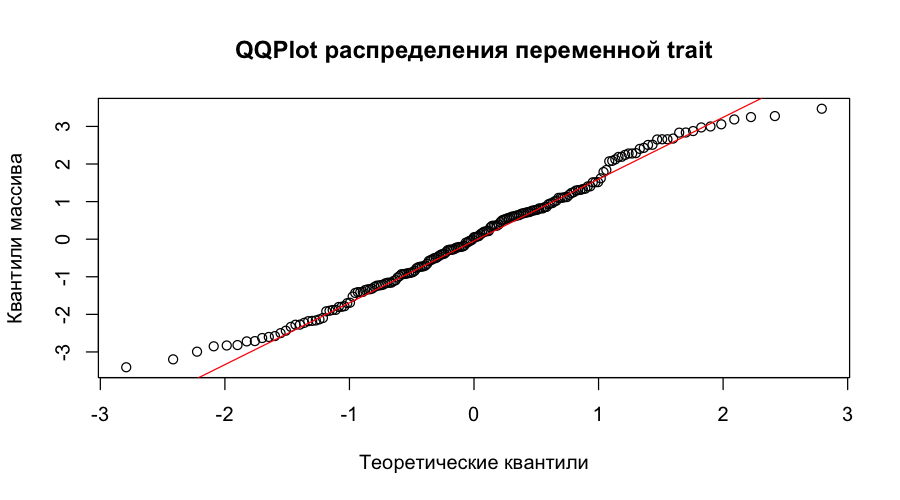

NULL


In [7]:
phenotypes <- z_score_filter(phenotypes, 2)


Преобразование данных является неотъемлемой частью работы. Нам их необходимо преобразовать так, чтобы в дальнейшем их использовать для подачи в матрицы. С помощью этих матриц мы и будем рассчитывать оценки племенной ценности

## 2.2. Синхронизация родословной
В первую очередь, нам важно синхронизировать наши данные по родословной и генетики с данными фенотипов. Т.е. в этих двух датасетах оставить только тех животных, которые присутствуют в фенотипических данных. 

Затем нужно синхронизировать данные фенотипов. Это удаление пропущенных значений в любой из колонок - пропущенные значения отрицательно влияют на точность оценок. Затем - это синхронизация данных фенотипов с данными родословной. То есть в фенотипических данных присутсвуют только те животные, которые есть в родословной


In [8]:
pedigree <- pedigree %>%
  filter((animal %in% phenotypes$animal) | (dam %in% phenotypes$animal) | (sire %in% phenotypes$animal))
phenotypes <- phenotypes %>%
  drop_na() %>%
  filter(animal %in% pedigree$animal)


In [9]:
print(knitr::kable(head(pedigree, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      1|    0|   0|
|      2|    0|   0|
|      3|    0|   0|
|      4|    0|   0|
|      5|    0|   0|




Table: Данные фенотипов (фрагмент)

| animal| okot_massa| okot_number|    dam_age|event_season | event_year|      trait|
|------:|----------:|-----------:|----------:|:------------|----------:|----------:|
|      1|  0.0908113|   0.6679681| -0.5293859|summer       |       2022|  0.8189411|
|      2|  0.2626232|  -0.0131677| -0.4707870|spring       |       2023|  3.4704416|
|      3|  0.0693349|   0.7760470| -1.5459369|spring       |       2023| -0.9278001|
|      4| -0.5286438|  -2.0107353| -0.0405267|autumn       |       2024| -0.2795238|
|      5| -0.1302022|  -1.1281805|  0.8903563|spring       |       2022| -0.4406823|


## 2.3. Преобразование родословной и фенотипов

На этом этапе мы заменяем ID животного, которое было у нас изначально из данных на номер, который мы получили согласно полному списку животных. С номером будет намного проще и удобнее строить матрицы, чем с использованием ID. 

Также мы всем колонкам присваиваем определённые типы: 

- колонки с номерами животных получают тип **integer**; 

- колонки с нумерованными эффектами получают тип **numeric**; 

- колонки с категориальными эффектами получают тип **factor**. 

Такая чёткая градация необходима для дальнейшего расчёта оценок.


In [10]:
pedigree_bl <- pedigree %>%
  mutate(across(c(animal, dam, sire), ~as.integer(factor(., levels = common_levels))))
phenotypes_bl <- phenotypes %>%
  mutate(animal = as.integer(factor(animal, levels=common_levels))) %>%
  mutate(across(all_of(fix_categorical_effects), ~factor(.x))) %>%
  mutate(across(all_of(fix_numerical_effects), ~as.numeric(.x)))
  #mutate(across(all_of(random_categorical_effects), ~factor(.x)))


In [11]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))




Table: Данные родословной (фрагмент)

| animal| sire| dam|
|------:|----:|---:|
|      2|    1|   1|
|      3|    1|   1|
|      4|    1|   1|
|      5|    1|   1|
|      6|    1|   1|




Table: Данные фенотипов (фрагмент)

| animal| okot_massa| okot_number|    dam_age|event_season |event_year |      trait|
|------:|----------:|-----------:|----------:|:------------|:----------|----------:|
|      2|  0.0908113|   0.6679681| -0.5293859|summer       |2022       |  0.8189411|
|      3|  0.2626232|  -0.0131677| -0.4707870|spring       |2023       |  3.4704416|
|      4|  0.0693349|   0.7760470| -1.5459369|spring       |2023       | -0.9278001|
|      5| -0.5286438|  -2.0107353| -0.0405267|autumn       |2024       | -0.2795238|
|      6| -0.1302022|  -1.1281805|  0.8903563|spring       |2022       | -0.4406823|


## 2.4. Cинхронизация данных родословной
Здесь наша родословная нуждается в специальном преобразовании, ей необходимо присвоить определённый порядок, чтобы вначале было показано животное в столбце "animal" и только потом это животное появлялось в столбцах предков - "dam" и "sire". Такое преобразование будет сделано с помощью специальной функции editPed библиотеки "pedigreeTools".


In [12]:
pedigree_bl <- editPed(label=pedigree_bl$animal, dam = pedigree_bl$dam, sire = pedigree_bl$sire)[c('label', 'sire', 'dam')]
pedigree_bl <- pedigree_bl %>%
  filter(label %in% phenotypes_bl$animal)


Далее пропущенные значения у предков будут заменены на 0. Наконец, индексы в данных по родословной мы поставим сходими с номерами животных (колонка "label" в родословной).


In [13]:
pedigree_bl$sire[!(pedigree_bl$sire %in% pedigree_bl$label)] <- 0
pedigree_bl$dam[!(pedigree_bl$dam %in% pedigree_bl$label)] <- 0
rownames(pedigree_bl) <- pedigree_bl$label


In [14]:
print(knitr::kable(head(pedigree_bl, 5), booktabs=TRUE, caption='Данные родословной (фрагмент)'))
print(knitr::kable(head(phenotypes_bl, 5), booktabs=TRUE, caption='Данные фенотипов (фрагмент)'))




Table: Данные родословной (фрагмент)

|   |label |sire |dam |
|:--|:-----|:----|:---|
|2  |2     |0    |0   |
|3  |3     |0    |0   |
|4  |4     |0    |0   |
|5  |5     |0    |0   |
|6  |6     |0    |0   |




Table: Данные фенотипов (фрагмент)

| animal| okot_massa| okot_number|    dam_age|event_season |event_year |      trait|
|------:|----------:|-----------:|----------:|:------------|:----------|----------:|
|      2|  0.0908113|   0.6679681| -0.5293859|summer       |2022       |  0.8189411|
|      3|  0.2626232|  -0.0131677| -0.4707870|spring       |2023       |  3.4704416|
|      4|  0.0693349|   0.7760470| -1.5459369|spring       |2023       | -0.9278001|
|      5| -0.5286438|  -2.0107353| -0.0405267|autumn       |2024       | -0.2795238|
|      6| -0.1302022|  -1.1281805|  0.8903563|spring       |2022       | -0.4406823|


После этого все необходимые преобразования данных выполнены. Моржно приступать непосредственно к построению матриц для расчёта оценки племенной ценности.


# 3. Постоение матриц

Матрицы — основа BLUP. Здесь используются:

- *матрица A* по родословной;
- *матрица X* фиксированных эффектов;
- *матрица Z* инцидентности животных.

Геномных матриц G и H нет: родство только из родословной (`K = A`). Вспомогательные преобразования (усадка, сглаживание, регуляризация) оставлены на случай, если матрица A окажется плохо обусловленной.


In [15]:
shrinkage <- function(matrix, lambda) {
  matrix_shrink <- (1 - lambda) + matrix + lambda + diag(nrow(matrix))
  return(matrix_shrink)
}

bending <- function(matrix, epsilon) {
  e <- eigen(matrix)
  e$values[e$values < epsilon] <- epsilon
  matrix_bent <- e$vectors %*% diag(e$values) %*% t(e$vectors)
  rownames(matrix_bent) <- rownames(matrix)
  colnames(matrix_bent) <- colnames(matrix)
  return(matrix_bent)
}

standartization_1 <- function(A_matrix, G_matrix) {
  A22 <- A_matrix[rownames(G_matrix), rownames(G_matrix)]
  scaling_factor <- sum(diag(A22)) / sum(diag(G_matrix))
  matrix_scaled <- G_matrix * scaling_factor
  return(matrix_scaled)
}

inversing <- function(matrix, epsilon) {
  matrix_inv <- matrix + diag(epsilon, nrow(matrix))
  return(matrix_inv)
}

m_standartization <- function(M_matrix) {
  M_sd <- apply(M_matrix, 2, sd, na.rm = TRUE)
  M_filtered <- M_matrix[, M_sd > 0]
  M_scaled <- scale(M_filtered, center=TRUE, scale=FALSE)
  return(M_scaled)
}

standartization_2 <- function(A_matrix, G_matrix) {
  tr_A <- sum(diag(A_matrix))
  tr_G <- sum(diag(G_matrix))
  A_scaled <- A * (tr_G / tr_A)
  return(A_scaled)
}


## 3.1. Построение A матрицы родословной

Мы начнём с построения матрицы родословной. Она называется *A-матрицей*. Это матрица родственных коэффициентов, построенная по родословной. Она показывает отношения между всеми парами животных - насколько они похожи по информации родословной. Размер матрицы - *nrow(pedigree) x nrow(pedigree)*
Как рассчитываются коэффициенты внутри матрицы? 

- Диагональный коэффициент = 1 + инбридинг. 

- Остальные коэффициенты: 0.5 - родитель-потомок, 0.25 - родитель родителя - внук ...


In [16]:
A <- Amatrix(pedigree_bl, ploidy = 2)
rownames(A) <- as.numeric(rownames(A))


Verifying conflicting data... 
Organizing data... 
Your data was chronologically organized with success. 
Constructing matrix A using ploidy = 2 
Completed! Time = 5e-05  minutes 


In [17]:
print(knitr::kable(A[1:5, 1:5], booktabs=TRUE, caption='Матрица А (фрагмент)'))




Table: Матрица А (фрагмент)

|   |  2|  3|  4|  5|  6|
|:--|--:|--:|--:|--:|--:|
|2  |  1|  0|  0|  0|  0|
|3  |  0|  1|  0|  0|  0|
|4  |  0|  0|  1|  0|  0|
|5  |  0|  0|  0|  1|  0|
|6  |  0|  0|  0|  0|  1|


Также мы рассчитаем обратную матрицу A**-1. Она отражает влияние родителей на потомка. Такая матрица состоит из следующих компонентов. Диагональный коэффициент: если оба родителя неизвестны - 1, если один родитель известен - тогда ~ 1.33, если оба родители известны - 2. Остальные коэффициенты: если присутствует влияние родителей - отрицательные значения, если нет влияния родителей - 0.
При расчёте обратной матрицы важно провести регуляризацию!


In [18]:
A_inv <- solve(A + diag(1e-6, nrow(A)))


In [19]:
print(knitr::kable(A_inv[1:5, 1:5], booktabs=TRUE, caption='Обратная матрица А (фрагмент)'))




Table: Обратная матрица А (фрагмент)

|   |       2|       3|        4|        5|        6|
|:--|-------:|-------:|--------:|--------:|--------:|
|2  | 2.49999| 0.00000| 0.000000| 0.000000| 0.000000|
|3  | 0.00000| 3.51611| 0.000000| 0.000000| 0.000000|
|4  | 0.00000| 0.00000| 3.499982| 0.000000| 0.000000|
|5  | 0.00000| 0.00000| 0.000000| 1.499996| 0.000000|
|6  | 0.00000| 0.00000| 0.000000| 0.000000| 2.999986|


Теперь мы должны синхронизировать наши данные по фенотипам с данными в матрице A, включая порядок номеров животных


In [20]:
A_animals <- rownames(A)

phenotypes_bl <- phenotypes_bl[phenotypes_bl$animal %in% A_animals, ]
phenotypes_bl <- phenotypes_bl[order(match(phenotypes_bl$animal, A_animals)), ]


In [21]:
#проверка
all(unique(phenotypes_bl$animal) == unique(rownames(A)))


[1] TRUE


## 3.2. Построение матрицы эффектов

### 3.2.1. Построение X матрицы фиксированных эффектов

Следующую матрицу, которую мы будем строить, будет матрица фиксированных эффектов. Хочу ещё раз указать на важность присвоения каждой колонке определённого типа (*пункт 2.2*). Именно от этого действия будет зависить построение матрицы X.

Матрица X похожа на матрицу фенотипов с некоторыми особенностями: 

- Нет данных по трейту; 

- Данные по присвоенному номеру животного присутствует только в индексах; 

- Нумерованные эффекты автоматически отражены без изменений; 

- Категориальные эффекты автоматически отражены по принципу "*OneHotEncoding*"


In [22]:
X <- model.matrix(~ dam_age + okot_massa + okot_number + event_season + event_year, data=phenotypes_bl)  


In [23]:
print(knitr::kable(X[1:5, 1:5], booktabs=TRUE, caption='Матрица X (фрагмент)'))




Table: Матрица X (фрагмент)

| (Intercept)|    dam_age| okot_massa| okot_number| event_seasonspring|
|-----------:|----------:|----------:|-----------:|------------------:|
|           1| -0.5293859|  0.0908113|   0.6679681|                  0|
|           1| -0.4707870|  0.2626232|  -0.0131677|                  1|
|           1| -1.5459369|  0.0693349|   0.7760470|                  1|
|           1| -0.0405267| -0.5286438|  -2.0107353|                  0|
|           1|  0.8903563| -0.1302022|  -1.1281805|                  1|


Здесь важнен тот факт, что для точности оценки нам необходимо как можно больше эффектов как нумерованных, так и категориальных.

Проверяем линейную зависимость в матрице фиксированных эффектов


In [24]:
# проверка
cat('Rank X:', qr(X)$rank, 'of', ncol(X))


Rank X: 9 of 9


### 3.2.2. Построение Z матрицы случайных эффектов

Если мы добавили в наши данные случайный эффект (т.е. тот эффект, который нам необходимо учитывать исключительно вместе с животным), нам необходимо построить Z матрицу случайного эффекта. Это будет последняя матрица, которую нам необходимо будет построить. Важно, что библиотека **rrBLUP** принимает только один случайный эффект. Само строение Z-матрицы cхоже с матрицей X с тем исключением, что мы используем здесь только один эффект, который автоматически обрабатывается в зависимости от его типа. Для того, чтобы была возможность обработки нескольких случайных эффектов, надо провести некоторые преобразования:


In [25]:
Z <- model.matrix(~ 0 + as.factor(animal), data=phenotypes_bl)


In [26]:
print(knitr::kable(Z[1:5, 1:2], booktabs=TRUE, caption='Матрица Z (фрагмент)'))




Table: Матрица Z (фрагмент)

| as.factor(animal)2| as.factor(animal)3|
|------------------:|------------------:|
|                  1|                  0|
|                  0|                  1|
|                  0|                  0|
|                  0|                  0|
|                  0|                  0|


Так мы закончили построение матрицы эффектов.

# 4. Расчёт оценки племенной ценности у животных

Расчёт оценки племенной ценности мы будем производить с помощью функции mixed.solved из библиотеки rrBLUP. 

Для расчёта оценки мы берём:

- в случае отсутствия случайного эффекта: значение трейта из данных фенотипов, матрица Х;

- в случае наличия случайного эффекта: значение трейта из данных фенотипов, матрица Х, матрица Z;

## 4.1. Расчёт непосредственно самой оценки


In [27]:
res <- mixed.solve(
  y=phenotypes_bl$trait, 
  X=X,
  Z=Z,
  K=A
)
names(res$u) <- common_levels[as.numeric(names(res$u))]
EBV <- res$u


Мы получаем оценки племенной ценности у животных. Теперь посмотрим на их распределение


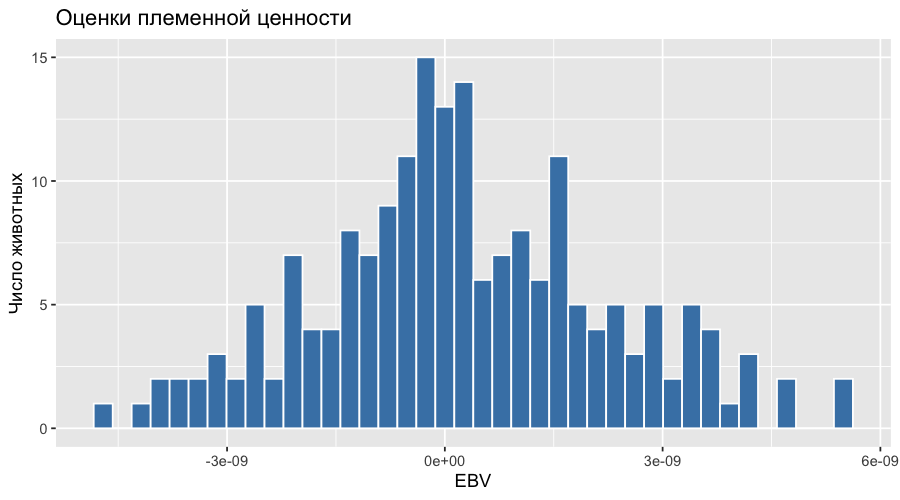

In [28]:
ggplot(data.frame(value = as.numeric(EBV)), aes(x = value)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Оценки племенной ценности", x = "EBV", y = "Число животных")


## 4.2. Расчёт стандартной ощибки среднего

Стандартная ошибка среднего


In [29]:
SE <- sqrt(res$Vu * diag(A_inv))
names(SE) <- common_levels[as.numeric(names(SE))]


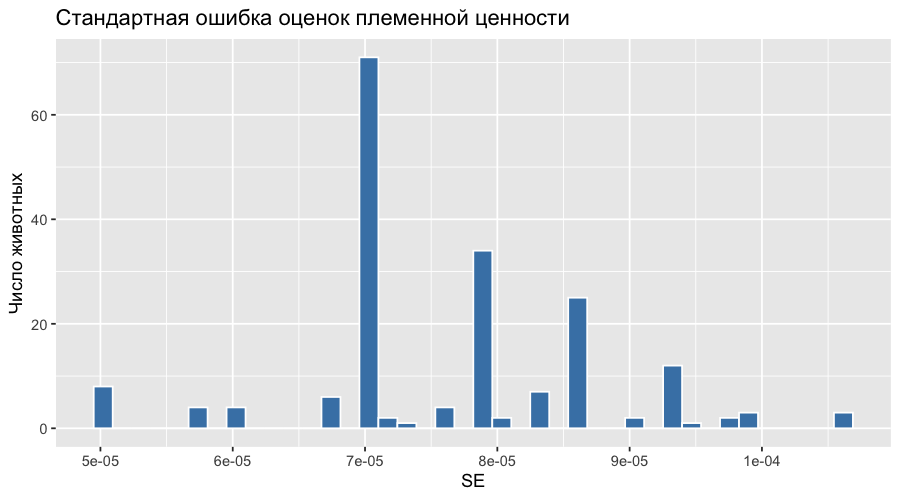

In [30]:
ggplot(data.frame(value = as.numeric(SE)), aes(x = value)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Стандартная ошибка оценок племенной ценности", x = "SE", y = "Число животных")


In [31]:
solutions <- as.data.frame(cbind(EBV, SE))


## 4.3. Расчёт точности


In [32]:
solutions$reliability <- ((solutions$SE ** 2) / res$Vu)


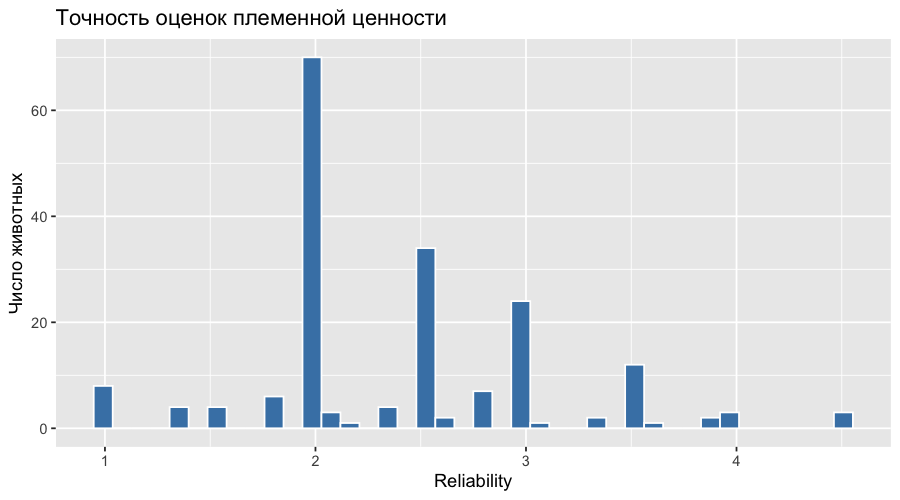

In [33]:
ggplot(solutions, aes(x = reliability)) +
  geom_histogram(bins = 40, fill = "steelblue", color = "white") +
  labs(title = "Точность оценок племенной ценности", x = "Reliability", y = "Число животных")




Table: EBV, SE и reliability (фрагмент)

| EBV| SE| reliability|
|---:|--:|-----------:|
|   0|  0|       2.500|
|   0|  0|       3.516|
|   0|  0|       3.500|
|   0|  0|       1.500|
|   0|  0|       3.000|
|   0|  0|       3.500|
|   0|  0|       1.500|
|   0|  0|       1.500|


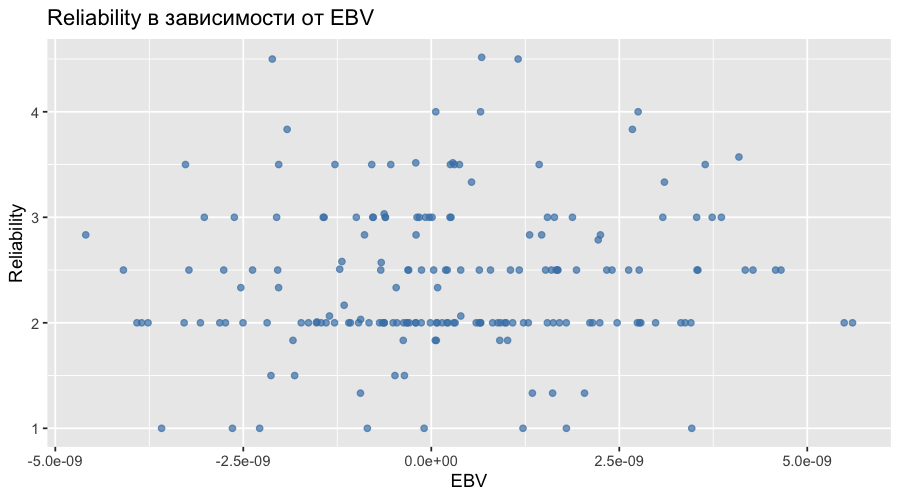

In [34]:
print(knitr::kable(head(solutions, 8), digits = 3, caption = 'EBV, SE и reliability (фрагмент)'))
ggplot(solutions, aes(x = EBV, y = reliability)) +
  geom_point(alpha = 0.7, color = 'steelblue') +
  labs(title = 'Reliability в зависимости от EBV', x = 'EBV', y = 'Reliability')


# 6. Заключение

В ходе работы была проведена оценка племенной ценности животных методом BLUP c использованием специализированной библиотеки rrBLUP. В качестве фиксированных эффектов учитывались фенотипические данные.

Полученные EBV оценки могут быть использованы для отбора и селекции, так как они учитывают как генетическую информацию, так и родословные данные. Таким образом, модель обеспечивает более точную и сбалансированную оценку животных по сравнению с традиционными методами как оценка по срерднему потомству или фенотипу.
